In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/fahmidachowdhury/lpbf-inconel/LPBF_in_final.xlsx


In [2]:


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Machine learning
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel, Matern, WhiteKernel
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import warnings
warnings.filterwarnings("ignore")

# Load dataset
file_path = "/kaggle/input/datasets/fahmidachowdhury/lpbf-inconel/LPBF_in_final.xlsx"

df = pd.read_excel(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

display(df.head())


Dataset shape: (203, 6)

Column names:
['Laser Power (W)', 'Scan Speed (mm/s)', 'Hatch space (mm)', 'Layer thickness (mm)', 'Spot size (mm)', 'RD_mean']


,Laser Power (W),Scan Speed (mm/s),Hatch space (mm),Layer thickness (mm),Spot size (mm),RD_mean
0,90,100,0.08,0.025,0.11,94.0320
1,90,200,0.08,0.025,0.11,99.0260
2,90,300,0.08,0.025,0.11,99.4497
3,90,400,0.08,0.025,0.11,99.6190
4,90,600,0.08,0.025,0.11,99.4920


In [3]:

df.columns = df.columns.str.strip()

# Standardize column names for easier processing
df.columns = (
    df.columns.str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Columns after standardization:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# Dataset information
print("\nDataset information:")
df.info()

# Statistical summary
display(df.describe().T)

# Remove exact duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

# Expected columns after standardization
print("\nCurrent dataset shape:", df.shape)


Columns after standardization:
['laser_power_w', 'scan_speed_mm_s', 'hatch_space_mm', 'layer_thickness_mm', 'spot_size_mm', 'rd_mean']

Missing values:
laser_power_w         0
scan_speed_mm_s       0
hatch_space_mm        0
layer_thickness_mm    0
spot_size_mm          0
rd_mean               0
dtype: int64

Duplicate rows: 0

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 203 entries, 0 to 202
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   laser_power_w       203 non-null    int64  
 1   scan_speed_mm_s     203 non-null    int64  
 2   hatch_space_mm      203 non-null    float64
 3   layer_thickness_mm  203 non-null    float64
 4   spot_size_mm        203 non-null    float64
 5   rd_mean             203 non-null    float64
dtypes: float64(4), int64(2)
memory usage: 9.6 KB


,count,mean,std,min,25%,50%,75%,max
laser_power_w,203.0,241.467980,79.972042,90.00,170.000,220.00,320.000,400.000
scan_speed_mm_s,203.0,910.492611,371.901394,100.00,645.000,800.00,1100.000,2000.000
hatch_space_mm,203.0,0.099704,0.026846,0.05,0.080,0.10,0.120,0.250
layer_thickness_mm,203.0,0.038916,0.008052,0.02,0.038,0.04,0.040,0.062
spot_size_mm,203.0,0.227493,0.154909,0.07,0.100,0.10,0.400,0.400
rd_mean,203.0,97.525825,2.655468,81.44,97.460,98.32,98.815,99.930



Current dataset shape: (203, 6)


In [4]:


# Original LPBF processing parameters
base_features = [
    "laser_power_w",
    "scan_speed_mm_s",
    "hatch_space_mm",
    "layer_thickness_mm",
    "spot_size_mm"
]

# Target variable
target = "rd_mean"

# Define X and y
X_raw = df[base_features].copy()
y = df[target].copy()

print("Total observations:", len(df))
print("Number of input features:", X_raw.shape[1])
print("Target variable:", target)

print("\nInput feature statistics:")
display(X_raw.describe().T)

print("\nTarget statistics:")
display(y.describe())


Total observations: 203
Number of input features: 5
Target variable: rd_mean

Input feature statistics:


,count,mean,std,min,25%,50%,75%,max
laser_power_w,203.0,241.467980,79.972042,90.00,170.000,220.00,320.00,400.000
scan_speed_mm_s,203.0,910.492611,371.901394,100.00,645.000,800.00,1100.00,2000.000
hatch_space_mm,203.0,0.099704,0.026846,0.05,0.080,0.10,0.12,0.250
layer_thickness_mm,203.0,0.038916,0.008052,0.02,0.038,0.04,0.04,0.062
spot_size_mm,203.0,0.227493,0.154909,0.07,0.100,0.10,0.40,0.400



Target statistics:


count    203.000000
mean      97.525825
std        2.655468
min       81.440000
25%       97.460000
50%       98.320000
75%       98.815000
max       99.930000
Name: rd_mean, dtype: float64

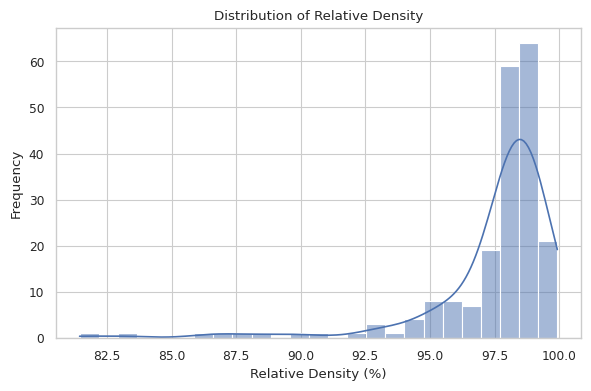

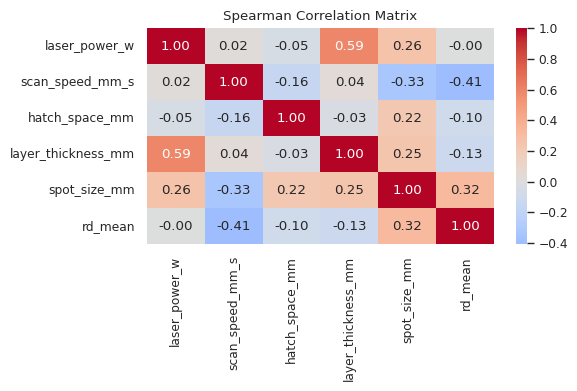

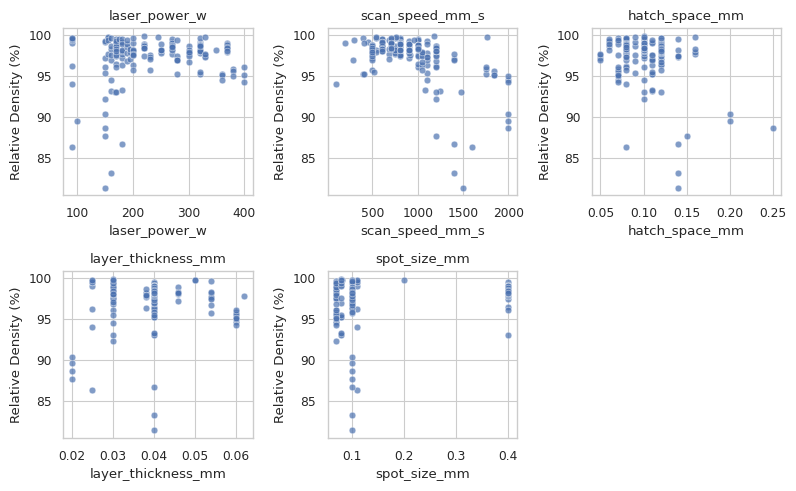

In [9]:


import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="paper")

# 1. Relative density distribution
fig, ax = plt.subplots(figsize=(6,4))

sns.histplot(
    df["rd_mean"],
    bins=25,
    kde=True,
    ax=ax
)

ax.set_xlabel("Relative Density (%)")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Relative Density")

plt.tight_layout()
plt.show()


# 2. Correlation heatmap
plt.figure(figsize=(6,4))

sns.heatmap(
    df[base_features + [target]].corr(method="spearman"),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout()
plt.show()


# 3. Processing parameters vs relative density
fig, axes = plt.subplots(2, 3, figsize=(8,5))

axes = axes.flatten()

for i, feature in enumerate(base_features):

    sns.scatterplot(
        data=df,
        x=feature,
        y="rd_mean",
        ax=axes[i],
        alpha=0.7
    )

    axes[i].set_title(feature)
    axes[i].set_ylabel("Relative Density (%)")


fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


In [10]:


import numpy as np
import pandas as pd

# Copy original input features
X_physics = X_raw.copy()

# Extract process parameters
P = X_physics["laser_power_w"]
v = X_physics["scan_speed_mm_s"]
h = X_physics["hatch_space_mm"]
t = X_physics["layer_thickness_mm"]
d = X_physics["spot_size_mm"]


# 1. Volumetric Energy Density (J/mm^3)
X_physics["VED"] = P / (v * h * t)


# 2. Linear Energy Density (J/mm)
X_physics["LED"] = P / v


# 3. Areal Energy Density (J/mm^2)
X_physics["AED"] = P / (v * h)


# 4. Beam-to-Hatch Ratio
X_physics["BHR"] = d / h


# 5. Beam-to-Layer Ratio
X_physics["BLR"] = d / t


# Display results
print("Original features:", len(base_features))
print("Total physics-informed features:", X_physics.shape[1])

print("\nFirst 10 observations:")
display(X_physics.head(10))

print("\nFeature statistics:")
display(X_physics.describe().T)


# Check for invalid values
assert np.isfinite(X_physics.values).all(), \
    "Invalid values detected in physics-informed features."

print("\nPhysics-informed feature engineering completed.")


Original features: 5
Total physics-informed features: 10

First 10 observations:


,laser_power_w,scan_speed_mm_s,hatch_space_mm,layer_thickness_mm,spot_size_mm,VED,LED,AED,BHR,BLR
0,90,100,0.08,0.025,0.11,450.000000,0.90000,11.250000,1.375000,4.400000
1,90,200,0.08,0.025,0.11,225.000000,0.45000,5.625000,1.375000,4.400000
2,90,300,0.08,0.025,0.11,150.000000,0.30000,3.750000,1.375000,4.400000
3,90,400,0.08,0.025,0.11,112.500000,0.22500,2.812500,1.375000,4.400000
4,90,600,0.08,0.025,0.11,75.000000,0.15000,1.875000,1.375000,4.400000
5,90,800,0.08,0.025,0.11,56.250000,0.11250,1.406250,1.375000,4.400000
6,90,1200,0.08,0.025,0.11,37.500000,0.07500,0.937500,1.375000,4.400000
7,90,1600,0.08,0.025,0.11,28.125000,0.05625,0.703125,1.375000,4.400000
8,100,2000,0.20,0.020,0.10,12.500000,0.05000,0.250000,0.500000,5.000000
9,150,800,0.06,0.030,0.07,104.166667,0.18750,3.125000,1.166667,2.333333



Feature statistics:


,count,mean,std,min,25%,50%,75%,max
laser_power_w,203.0,241.467980,79.972042,90.000000,170.000000,220.000000,320.000000,400.000
scan_speed_mm_s,203.0,910.492611,371.901394,100.000000,645.000000,800.000000,1100.000000,2000.000
hatch_space_mm,203.0,0.099704,0.026846,0.050000,0.080000,0.100000,0.120000,0.250
layer_thickness_mm,203.0,0.038916,0.008052,0.020000,0.038000,0.040000,0.040000,0.062
spot_size_mm,203.0,0.227493,0.154909,0.070000,0.100000,0.100000,0.400000,0.400
VED,203.0,84.473338,47.943653,12.500000,54.710884,75.000000,102.405395,450.000
LED,203.0,0.307623,0.155706,0.050000,0.190476,0.277778,0.392247,0.900
AED,203.0,3.243977,1.699728,0.250000,2.091049,2.812500,4.000000,11.250
BHR,203.0,2.366604,1.643038,0.400000,0.854167,1.375000,4.000000,5.000
BLR,203.0,5.855588,3.765978,1.166667,2.333333,4.400000,10.000000,10.000



Physics-informed feature engineering completed.


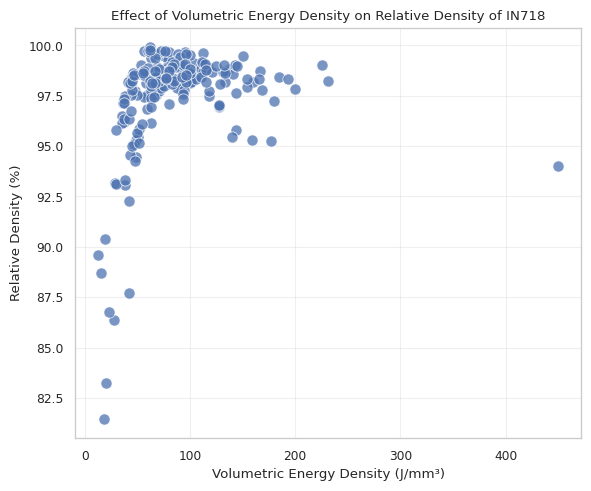

Pearson correlation: 0.2691
Spearman correlation: 0.3868


count    203.000000
mean      84.473338
std       47.943653
min       12.500000
25%       54.710884
50%       75.000000
75%      102.405395
max      450.000000
Name: VED, dtype: float64

In [12]:

#VED VS RELATIVE DENSITY


import matplotlib.pyplot as plt
import seaborn as sns

# Create analysis dataframe
ved_df = X_physics[["VED"]].copy()
ved_df["RD_mean"] = y

# Scatter plot
plt.figure(figsize=(6,5))

sns.scatterplot(
    data=ved_df,
    x="VED",
    y="RD_mean",
    s=65,
    alpha=0.75
)

plt.xlabel("Volumetric Energy Density (J/mm³)")
plt.ylabel("Relative Density (%)")

plt.title(
    "Effect of Volumetric Energy Density on Relative Density of IN718"
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Correlation analysis
pearson = ved_df["VED"].corr(
    ved_df["RD_mean"],
    method="pearson"
)

spearman = ved_df["VED"].corr(
    ved_df["RD_mean"],
    method="spearman"
)

print("Pearson correlation:", round(pearson, 4))
print("Spearman correlation:", round(spearman, 4))


# VED descriptive statistics
display(ved_df["VED"].describe())


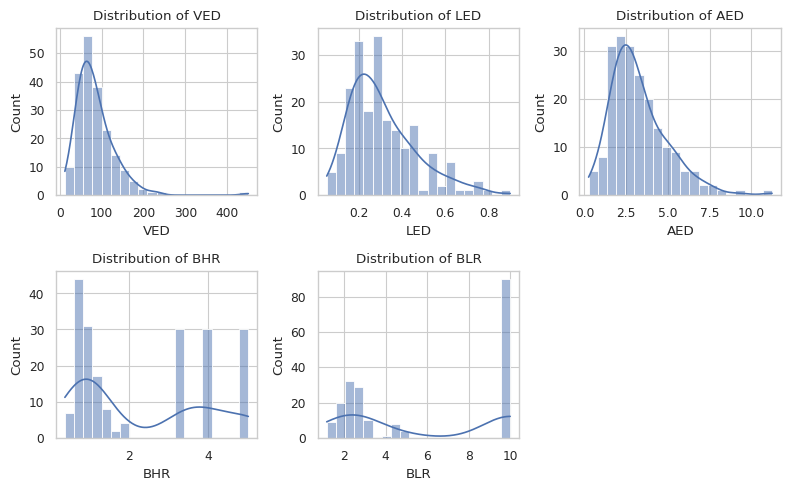

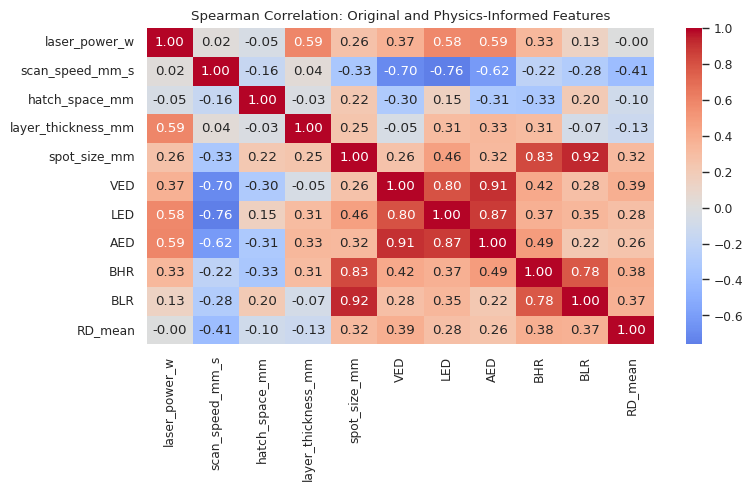

In [15]:


#PHYSICS FEATURE DISTRIBUTIONS

physics_features = [
    "VED",
    "LED",
    "AED",
    "BHR",
    "BLR"
]

fig, axes = plt.subplots(2, 3, figsize=(8,5))

axes = axes.flatten()

for i, feature in enumerate(physics_features):

    sns.histplot(
        X_physics[feature],
        kde=True,
        ax=axes[i],
        bins=20
    )

    axes[i].set_title(f"Distribution of {feature}")

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()


# Correlation between engineered features and relative density
corr_data = X_physics.copy()
corr_data["RD_mean"] = y

plt.figure(figsize=(8,5))

sns.heatmap(
    corr_data.corr(method="spearman"),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Spearman Correlation: Original and Physics-Informed Features")
plt.tight_layout()
plt.show()


In [16]:


from sklearn.model_selection import train_test_split, KFold

# Split indices to ensure identical observations
train_idx, test_idx = train_test_split(
    X_raw.index,
    test_size=0.20,
    random_state=42
)

# Conventional features
X_train_raw = X_raw.loc[train_idx].copy()
X_test_raw = X_raw.loc[test_idx].copy()

# Physics-informed features
X_train_physics = X_physics.loc[train_idx].copy()
X_test_physics = X_physics.loc[test_idx].copy()

# Target
y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()

print("Training samples:", len(X_train_raw))
print("Testing samples:", len(X_test_raw))

print("\nConventional ML training shape:", X_train_raw.shape)
print("Physics-informed training shape:", X_train_physics.shape)

print("\nTraining target distribution:")
display(y_train.describe())

print("\nTesting target distribution:")
display(y_test.describe())


# 5-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("\n5-fold cross-validation is ready.")


Training samples: 162
Testing samples: 41

Conventional ML training shape: (162, 5)
Physics-informed training shape: (162, 10)

Training target distribution:


count    162.000000
mean      97.734164
std        1.936177
min       86.370000
25%       97.472500
50%       98.315000
75%       98.787500
max       99.930000
Name: rd_mean, dtype: float64


Testing target distribution:


count    41.000000
mean     96.702634
std       4.432934
min      81.440000
25%      97.410000
50%      98.440000
75%      98.920000
max      99.650000
Name: rd_mean, dtype: float64


5-fold cross-validation is ready.


In [17]:


!pip install xgboost -q


import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

# Preprocessing
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Machine learning models
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    GradientBoostingRegressor,
    HistGradientBoostingRegressor
)

from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge
from sklearn.neural_network import MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor

from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    Matern,
    WhiteKernel
)

from xgboost import XGBRegressor

# Evaluation
from sklearn.model_selection import (
    KFold,
    cross_validate
)

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

print("All libraries imported successfully.")


All libraries imported successfully.


In [18]:

def create_models():

    models = {

        # 1. Random Forest
        "RF": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", RandomForestRegressor(
                n_estimators=300,
                max_depth=8,
                min_samples_split=4,
                min_samples_leaf=2,
                max_features=0.8,
                random_state=42,
                n_jobs=-1
            ))
        ]),

        # 2. Extra Trees
        "ET": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", ExtraTreesRegressor(
                n_estimators=300,
                max_depth=8,
                min_samples_split=4,
                min_samples_leaf=2,
                max_features=0.8,
                random_state=42,
                n_jobs=-1
            ))
        ]),

        # 3. Gradient Boosting
        "GB": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", GradientBoostingRegressor(
                n_estimators=150,
                learning_rate=0.03,
                max_depth=2,
                min_samples_leaf=3,
                loss="huber",
                random_state=42
            ))
        ]),

        # 4. Histogram Gradient Boosting
        "HistGB": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", HistGradientBoostingRegressor(
                max_iter=150,
                learning_rate=0.04,
                max_leaf_nodes=10,
                l2_regularization=2.0,
                random_state=42
            ))
        ]),

        # 5. XGBoost
        "XGBoost": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("model", XGBRegressor(
                n_estimators=200,
                learning_rate=0.03,
                max_depth=2,
                min_child_weight=3,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_lambda=2,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=1
            ))
        ]),

        # 6. Support Vector Regression
        "SVR": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", SVR(
                kernel="rbf",
                C=10,
                epsilon=0.1,
                gamma="scale"
            ))
        ]),

        # 7. K-Nearest Neighbors
        "KNN": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", KNeighborsRegressor(
                n_neighbors=5,
                weights="distance",
                p=2
            ))
        ]),

        # 8. Artificial Neural Network
        "ANN": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", MLPRegressor(
                hidden_layer_sizes=(64, 32),
                activation="relu",
                solver="adam",
                alpha=0.01,
                learning_rate_init=0.001,
                max_iter=3000,
                early_stopping=True,
                validation_fraction=0.15,
                n_iter_no_change=50,
                random_state=42
            ))
        ]),

        # 9. Gaussian Process Regression
        "GPR": Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", GaussianProcessRegressor(
                kernel=(
                    ConstantKernel(1.0) *
                    Matern(length_scale=1.0, nu=2.5) +
                    WhiteKernel(noise_level=0.1)
                ),
                normalize_y=True,
                n_restarts_optimizer=3,
                random_state=42
            ))
        ])

    }

    return models


models = create_models()

print("Total models:", len(models))

for name in models:
    print(name)


Total models: 9
RF
ET
GB
HistGB
XGBoost
SVR
KNN
ANN
GPR


In [19]:


results = []

trained_models = {}

feature_sets = {

    "Conventional ML": (
        X_train_raw,
        X_test_raw
    ),

    "Physics-Informed ML": (
        X_train_physics,
        X_test_physics
    )

}

# Five-fold cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


for feature_name, (Xtr, Xte) in feature_sets.items():

    print("\n" + "=" * 65)
    print("FEATURE SET:", feature_name)
    print("=" * 65)

    for model_name, model in create_models().items():

        print(f"\nTraining {model_name}...")

        # Cross-validation using training data only
        cv_scores = cross_validate(
            model,
            Xtr,
            y_train,
            cv=cv,
            scoring={
                "r2": "r2",
                "mae": "neg_mean_absolute_error",
                "rmse": "neg_root_mean_squared_error"
            },
            n_jobs=1
        )

        # Fit model on complete training set
        model.fit(Xtr, y_train)

        # Training predictions
        train_pred = model.predict(Xtr)

        # Testing predictions
        test_pred = model.predict(Xte)

        # Training metrics
        train_r2 = r2_score(
            y_train,
            train_pred
        )

        train_rmse = np.sqrt(
            mean_squared_error(y_train, train_pred)
        )

        # Testing metrics
        test_r2 = r2_score(
            y_test,
            test_pred
        )

        test_mae = mean_absolute_error(
            y_test,
            test_pred
        )

        test_rmse = np.sqrt(
            mean_squared_error(y_test, test_pred)
        )

        # Cross-validation metrics
        cv_r2 = cv_scores["test_r2"].mean()

        cv_r2_std = cv_scores["test_r2"].std()

        cv_mae = -cv_scores["test_mae"].mean()

        cv_rmse = -cv_scores["test_rmse"].mean()

        # Save results
        results.append({

            "Feature Set": feature_name,

            "Model": model_name,

            "Train R2": train_r2,

            "Train RMSE": train_rmse,

            "CV R2": cv_r2,

            "CV R2 Std": cv_r2_std,

            "CV MAE": cv_mae,

            "CV RMSE": cv_rmse,

            "Test R2": test_r2,

            "Test MAE": test_mae,

            "Test RMSE": test_rmse

        })

        # Store trained model
        trained_models[
            (feature_name, model_name)
        ] = model

        print(
            f"Train R2 = {train_r2:.4f} | "
            f"CV R2 = {cv_r2:.4f} | "
            f"Test R2 = {test_r2:.4f} | "
            f"Test RMSE = {test_rmse:.4f}"
        )


# Convert results to dataframe
results_df = pd.DataFrame(results)

# Sort by test RMSE
results_df = results_df.sort_values(
    by="Test RMSE",
    ascending=True
).reset_index(drop=True)


print("\nFINAL MODEL RESULTS")

display(
    results_df.style.format({
        "Train R2": "{:.4f}",
        "Train RMSE": "{:.4f}",
        "CV R2": "{:.4f}",
        "CV R2 Std": "{:.4f}",
        "CV MAE": "{:.4f}",
        "CV RMSE": "{:.4f}",
        "Test R2": "{:.4f}",
        "Test MAE": "{:.4f}",
        "Test RMSE": "{:.4f}"
    })
)



FEATURE SET: Conventional ML

Training RF...
Train R2 = 0.8510 | CV R2 = -0.0725 | Test R2 = 0.5190 | Test RMSE = 3.0368

Training ET...
Train R2 = 0.8359 | CV R2 = -0.3016 | Test R2 = 0.3903 | Test RMSE = 3.4188

Training GB...
Train R2 = 0.7072 | CV R2 = 0.0432 | Test R2 = 0.5034 | Test RMSE = 3.0855

Training HistGB...
Train R2 = 0.6357 | CV R2 = -0.0655 | Test R2 = 0.4742 | Test RMSE = 3.1749

Training XGBoost...
Train R2 = 0.7693 | CV R2 = -0.0267 | Test R2 = 0.5759 | Test RMSE = 2.8513

Training SVR...
Train R2 = 0.8425 | CV R2 = 0.2562 | Test R2 = 0.4829 | Test RMSE = 3.1486

Training KNN...
Train R2 = 1.0000 | CV R2 = -0.0114 | Test R2 = 0.2570 | Test RMSE = 3.7743

Training ANN...
Train R2 = 0.0411 | CV R2 = -13.1305 | Test R2 = -0.0372 | Test RMSE = 4.4593

Training GPR...
Train R2 = 0.9351 | CV R2 = 0.3358 | Test R2 = 0.6334 | Test RMSE = 2.6511

FEATURE SET: Physics-Informed ML

Training RF...
Train R2 = 0.9146 | CV R2 = 0.5207 | Test R2 = 0.6852 | Test RMSE = 2.4567

Trai

,Feature Set,Model,Train R2,Train RMSE,CV R2,CV R2 Std,CV MAE,CV RMSE,Test R2,Test MAE,Test RMSE
0,Physics-Informed ML,XGBoost,0.8567,0.7306,0.3355,0.6395,0.7333,1.1108,0.7219,1.2023,2.3092
1,Physics-Informed ML,RF,0.9146,0.5640,0.5207,0.4059,0.6380,1.0046,0.6852,1.1850,2.4567
2,Physics-Informed ML,GB,0.8426,0.7658,0.3688,0.5162,0.7524,1.1791,0.6463,1.3099,2.6041
3,Conventional ML,GPR,0.9351,0.4916,0.3358,0.5945,0.7359,1.2014,0.6334,1.3221,2.6511
4,Physics-Informed ML,GPR,0.9548,0.4105,0.2434,0.7708,0.7328,1.2231,0.6109,1.2905,2.7311
5,Physics-Informed ML,ET,0.9294,0.5127,0.3450,0.6944,0.6418,1.0884,0.6067,1.2364,2.7459
6,Physics-Informed ML,SVR,0.8498,0.7480,0.2083,0.8312,0.7342,1.2336,0.5829,1.3232,2.8278
7,Conventional ML,XGBoost,0.7693,0.9270,-0.0267,1.0346,0.8481,1.3823,0.5759,1.3509,2.8513
8,Physics-Informed ML,HistGB,0.7557,0.9539,0.2832,0.4732,0.8499,1.3190,0.5596,1.4712,2.9057
9,Conventional ML,RF,0.8510,0.7451,-0.0725,1.1763,0.8300,1.3829,0.5190,1.3832,3.0368


TRAINING DATA


count    162.000000
mean      97.734164
std        1.936177
min       86.370000
25%       97.472500
50%       98.315000
75%       98.787500
max       99.930000
Name: rd_mean, dtype: float64


TESTING DATA


count    41.000000
mean     96.702634
std       4.432934
min      81.440000
25%      97.410000
50%      98.440000
75%      98.920000
max      99.650000
Name: rd_mean, dtype: float64

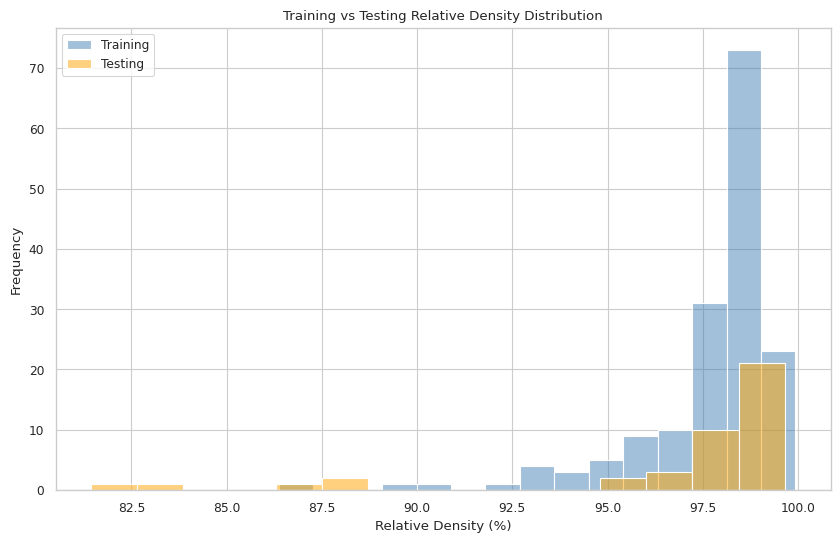

,Training,Testing
rd_mean,,
<90%,2,5
90-95%,10,0
95-97%,20,4
97-99%,103,24
99-100%,27,8


In [20]:

# COMPARE DATA DISTRIBUTIONS


print("TRAINING DATA")
display(y_train.describe())

print("\nTESTING DATA")
display(y_test.describe())


# Density distribution comparison
plt.figure(figsize=(10, 6))

sns.histplot(
    y_train,
    bins=15,
    color="steelblue",
    label="Training",
    alpha=0.5
)

sns.histplot(
    y_test,
    bins=15,
    color="orange",
    label="Testing",
    alpha=0.5
)

plt.xlabel("Relative Density (%)")
plt.ylabel("Frequency")
plt.title("Training vs Testing Relative Density Distribution")

plt.legend()
plt.show()


# Density category distribution
bins = [0, 90, 95, 97, 99, 100]
labels = [
    "<90%",
    "90-95%",
    "95-97%",
    "97-99%",
    "99-100%"
]

train_categories = pd.cut(
    y_train,
    bins=bins,
    labels=labels,
    include_lowest=True
)

test_categories = pd.cut(
    y_test,
    bins=bins,
    labels=labels,
    include_lowest=True
)

distribution = pd.DataFrame({
    "Training": train_categories.value_counts(sort=False),
    "Testing": test_categories.value_counts(sort=False)
})

display(distribution)


In [21]:


from sklearn.model_selection import train_test_split

# Create density categories
density_bins = [0, 95, 97, 99, 100]

density_labels = [
    "Low",
    "Medium",
    "High",
    "Very High"
]

y_categories = pd.cut(
    y,
    bins=density_bins,
    labels=density_labels,
    include_lowest=True
)

# Check category counts
print("Original density distribution:")
display(y_categories.value_counts().sort_index())


# Stratified split
train_idx, test_idx = train_test_split(
    X_raw.index,
    test_size=0.20,
    random_state=42,
    stratify=y_categories
)


# Recreate conventional features
X_train_raw = X_raw.loc[train_idx].copy()
X_test_raw = X_raw.loc[test_idx].copy()


# Recreate physics-informed features
X_train_physics = X_physics.loc[train_idx].copy()
X_test_physics = X_physics.loc[test_idx].copy()


# Recreate target variables
y_train = y.loc[train_idx].copy()
y_test = y.loc[test_idx].copy()


print("\nTraining observations:", len(y_train))
print("Testing observations:", len(y_test))


# Compare distributions
train_categories = y_categories.loc[train_idx]
test_categories = y_categories.loc[test_idx]

distribution = pd.DataFrame({

    "Original": y_categories.value_counts().sort_index(),

    "Training": train_categories.value_counts().sort_index(),

    "Testing": test_categories.value_counts().sort_index()

})

display(distribution)


Original density distribution:


rd_mean
Low           17
Medium        24
High         127
Very High     35
Name: count, dtype: int64


Training observations: 162
Testing observations: 41


,Original,Training,Testing
rd_mean,,,
Low,17,14,3
Medium,24,19,5
High,127,101,26
Very High,35,28,7


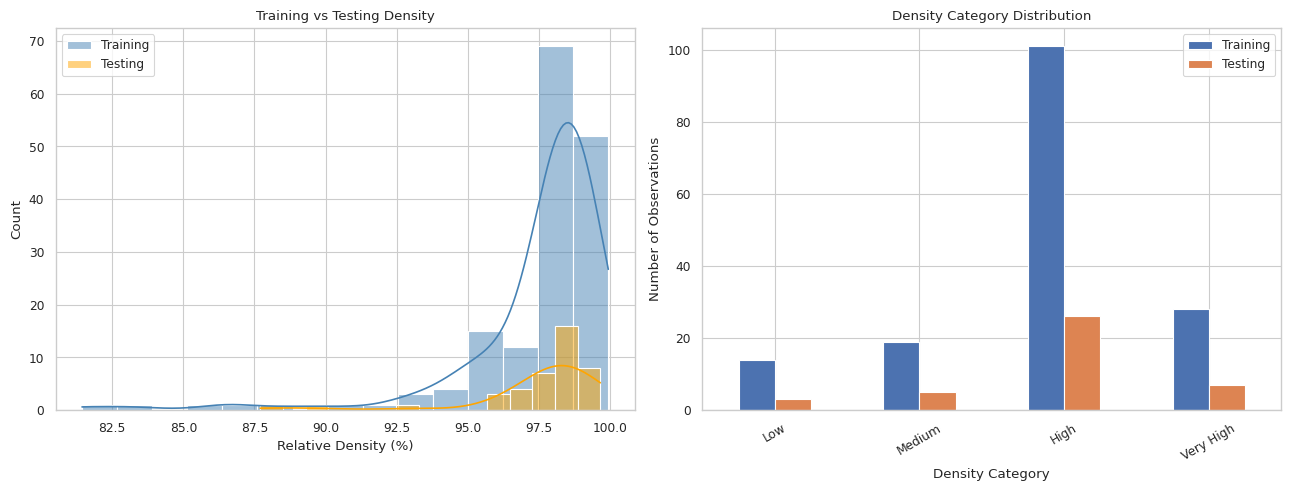

Training statistics:


count    162.000000
mean      97.512858
std        2.729638
min       81.440000
25%       97.455000
50%       98.372500
75%       98.832500
max       99.930000
Name: rd_mean, dtype: float64


Testing statistics:


count    41.000000
mean     97.577062
std       2.369973
min      87.700000
25%      97.570000
50%      98.130000
75%      98.740000
max      99.650000
Name: rd_mean, dtype: float64

In [22]:



fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Density distributions
sns.histplot(
    y_train,
    bins=15,
    kde=True,
    ax=axes[0],
    label="Training",
    color="steelblue",
    alpha=0.5
)

sns.histplot(
    y_test,
    bins=15,
    kde=True,
    ax=axes[0],
    label="Testing",
    color="orange",
    alpha=0.5
)

axes[0].set_title("Training vs Testing Density")
axes[0].set_xlabel("Relative Density (%)")
axes[0].legend()


# Density categories
distribution[["Training", "Testing"]].plot(
    kind="bar",
    ax=axes[1]
)

axes[1].set_title("Density Category Distribution")
axes[1].set_xlabel("Density Category")
axes[1].set_ylabel("Number of Observations")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


# Statistical comparison
print("Training statistics:")
display(y_train.describe())

print("\nTesting statistics:")
display(y_test.describe())


In [23]:

#STRATIFIED 5-FOLD CROSS-VALIDATION


from sklearn.model_selection import StratifiedKFold

# Density categories for training observations
y_train_categories = y_categories.loc[train_idx]

# Stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Check the distribution in each fold
for fold, (_, val_idx) in enumerate(
    cv.split(X_train_raw, y_train_categories),
    start=1
):

    fold_categories = y_train_categories.iloc[val_idx]

    print(f"\nFold {fold}")

    print(
        fold_categories.value_counts().sort_index()
    )

print("\nStratified 5-fold CV is ready.")



Fold 1
rd_mean
Low           3
Medium        4
High         20
Very High     6
Name: count, dtype: int64

Fold 2
rd_mean
Low           3
Medium        4
High         20
Very High     6
Name: count, dtype: int64

Fold 3
rd_mean
Low           2
Medium        3
High         21
Very High     6
Name: count, dtype: int64

Fold 4
rd_mean
Low           3
Medium        4
High         20
Very High     5
Name: count, dtype: int64

Fold 5
rd_mean
Low           3
Medium        4
High         20
Very High     5
Name: count, dtype: int64

Stratified 5-fold CV is ready.


In [24]:

#STRATIFIED CV MODEL EVALUATION


from sklearn.model_selection import cross_validate
from sklearn.base import clone

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import pandas as pd


# Generate stratified folds using density categories
cv_splits = list(
    cv.split(X_train_raw, y_train_categories)
)

print("Number of CV folds:", len(cv_splits))


# Define feature sets
feature_sets = {

    "Conventional ML": (
        X_train_raw,
        X_test_raw
    ),

    "Physics-Informed ML": (
        X_train_physics,
        X_test_physics
    )

}


# Store results and trained models
results_stratified = []

trained_models_stratified = {}


# Evaluate both feature sets
for feature_name, (Xtr, Xte) in feature_sets.items():

    print("\n" + "=" * 65)
    print("FEATURE SET:", feature_name)
    print("=" * 65)

    for model_name, model in create_models().items():

        print("\nTraining:", model_name)

        # Stratified cross-validation
        cv_scores = cross_validate(

            estimator=model,

            X=Xtr,

            y=y_train,

            cv=cv_splits,

            scoring={

                "r2": "r2",

                "mae": "neg_mean_absolute_error",

                "rmse": "neg_root_mean_squared_error"

            },

            n_jobs=1

        )


        # Fit model on complete training set
        model.fit(Xtr, y_train)


        # Training predictions
        train_pred = model.predict(Xtr)


        # Testing predictions
        test_pred = model.predict(Xte)


        # Training metrics
        train_r2 = r2_score(
            y_train,
            train_pred
        )

        train_rmse = np.sqrt(
            mean_squared_error(
                y_train,
                train_pred
            )
        )


        # Testing metrics
        test_r2 = r2_score(
            y_test,
            test_pred
        )

        test_mae = mean_absolute_error(
            y_test,
            test_pred
        )

        test_rmse = np.sqrt(
            mean_squared_error(
                y_test,
                test_pred
            )
        )


        # Cross-validation metrics
        cv_r2 = cv_scores["test_r2"].mean()

        cv_r2_std = cv_scores["test_r2"].std()

        cv_mae = -cv_scores["test_mae"].mean()

        cv_rmse = -cv_scores["test_rmse"].mean()


        # Save results
        results_stratified.append({

            "Feature Set": feature_name,

            "Model": model_name,

            "Train R2": train_r2,

            "Train RMSE": train_rmse,

            "CV R2": cv_r2,

            "CV R2 Std": cv_r2_std,

            "CV MAE": cv_mae,

            "CV RMSE": cv_rmse,

            "Test R2": test_r2,

            "Test MAE": test_mae,

            "Test RMSE": test_rmse

        })


        # Store fitted models
        trained_models_stratified[
            (feature_name, model_name)
        ] = model


        print(
            f"Train R2: {train_r2:.4f} | "
            f"CV R2: {cv_r2:.4f} | "
            f"Test R2: {test_r2:.4f} | "
            f"Test RMSE: {test_rmse:.4f}"
        )


# Create final results table
results_stratified_df = pd.DataFrame(
    results_stratified
)


# Sort by test RMSE
results_stratified_df = results_stratified_df.sort_values(
    "Test RMSE",
    ascending=True
).reset_index(drop=True)


print("\nFINAL STRATIFIED CV RESULTS")


display(
    results_stratified_df.style.format({

        "Train R2": "{:.4f}",

        "Train RMSE": "{:.4f}",

        "CV R2": "{:.4f}",

        "CV R2 Std": "{:.4f}",

        "CV MAE": "{:.4f}",

        "CV RMSE": "{:.4f}",

        "Test R2": "{:.4f}",

        "Test MAE": "{:.4f}",

        "Test RMSE": "{:.4f}"

    })
)


Number of CV folds: 5

FEATURE SET: Conventional ML

Training: RF
Train R2: 0.8858 | CV R2: 0.5630 | Test R2: 0.7349 | Test RMSE: 1.2054

Training: ET
Train R2: 0.9095 | CV R2: 0.6912 | Test R2: 0.8285 | Test RMSE: 0.9695

Training: GB
Train R2: 0.8151 | CV R2: 0.3891 | Test R2: 0.4782 | Test RMSE: 1.6910

Training: HistGB
Train R2: 0.6811 | CV R2: 0.4899 | Test R2: 0.7753 | Test RMSE: 1.1096

Training: XGBoost
Train R2: 0.8492 | CV R2: 0.6096 | Test R2: 0.6294 | Test RMSE: 1.4250

Training: SVR
Train R2: 0.9152 | CV R2: 0.6899 | Test R2: 0.7401 | Test RMSE: 1.1934

Training: KNN
Train R2: 1.0000 | CV R2: 0.6740 | Test R2: 0.3540 | Test RMSE: 1.8815

Training: ANN
Train R2: 0.3188 | CV R2: -8.0111 | Test R2: -1.5064 | Test RMSE: 3.7060

Training: GPR
Train R2: 0.9701 | CV R2: 0.6884 | Test R2: 0.6978 | Test RMSE: 1.2869

FEATURE SET: Physics-Informed ML

Training: RF
Train R2: 0.9416 | CV R2: 0.7757 | Test R2: 0.8722 | Test RMSE: 0.8370

Training: ET
Train R2: 0.9602 | CV R2: 0.7791 | 

,Feature Set,Model,Train R2,Train RMSE,CV R2,CV R2 Std,CV MAE,CV RMSE,Test R2,Test MAE,Test RMSE
0,Physics-Informed ML,ET,0.9602,0.5426,0.7791,0.0698,0.7297,1.2365,0.8733,0.4939,0.8334
1,Physics-Informed ML,RF,0.9416,0.6575,0.7757,0.0509,0.7457,1.2651,0.8722,0.5462,0.8370
2,Physics-Informed ML,HistGB,0.7350,1.4008,0.5848,0.1193,1.0612,1.7161,0.8708,0.6030,0.8415
3,Conventional ML,ET,0.9095,0.8184,0.6912,0.0699,0.8697,1.4731,0.8285,0.5751,0.9695
4,Conventional ML,HistGB,0.6811,1.5366,0.4899,0.0696,1.1096,1.9143,0.7753,0.7881,1.1096
5,Physics-Informed ML,GB,0.9082,0.8243,0.6820,0.0712,0.9070,1.4986,0.7647,0.6410,1.1355
6,Physics-Informed ML,XGBoost,0.9155,0.7912,0.7048,0.0846,0.9313,1.4470,0.7636,0.6464,1.1382
7,Conventional ML,SVR,0.9152,0.7925,0.6899,0.1600,0.8111,1.4144,0.7401,0.7337,1.1934
8,Conventional ML,RF,0.8858,0.9195,0.5630,0.2442,0.9658,1.7038,0.7349,0.6624,1.2054
9,Physics-Informed ML,SVR,0.8931,0.8897,0.6920,0.1243,0.8009,1.4534,0.7299,0.6842,1.2166


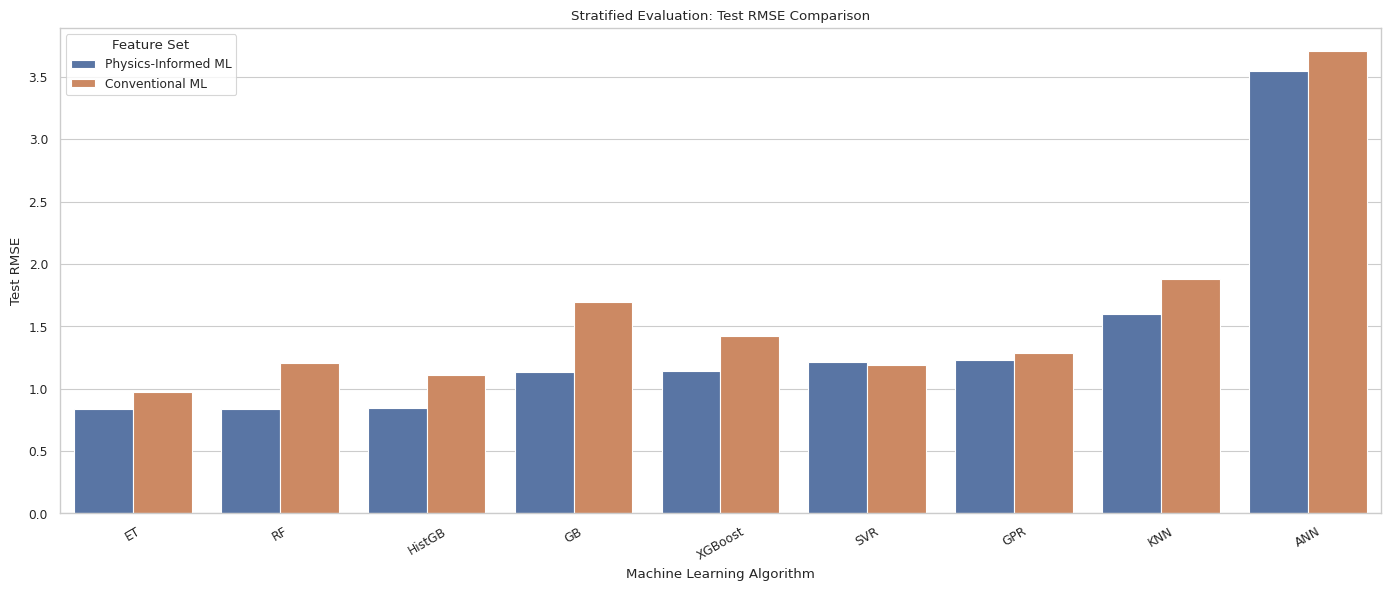

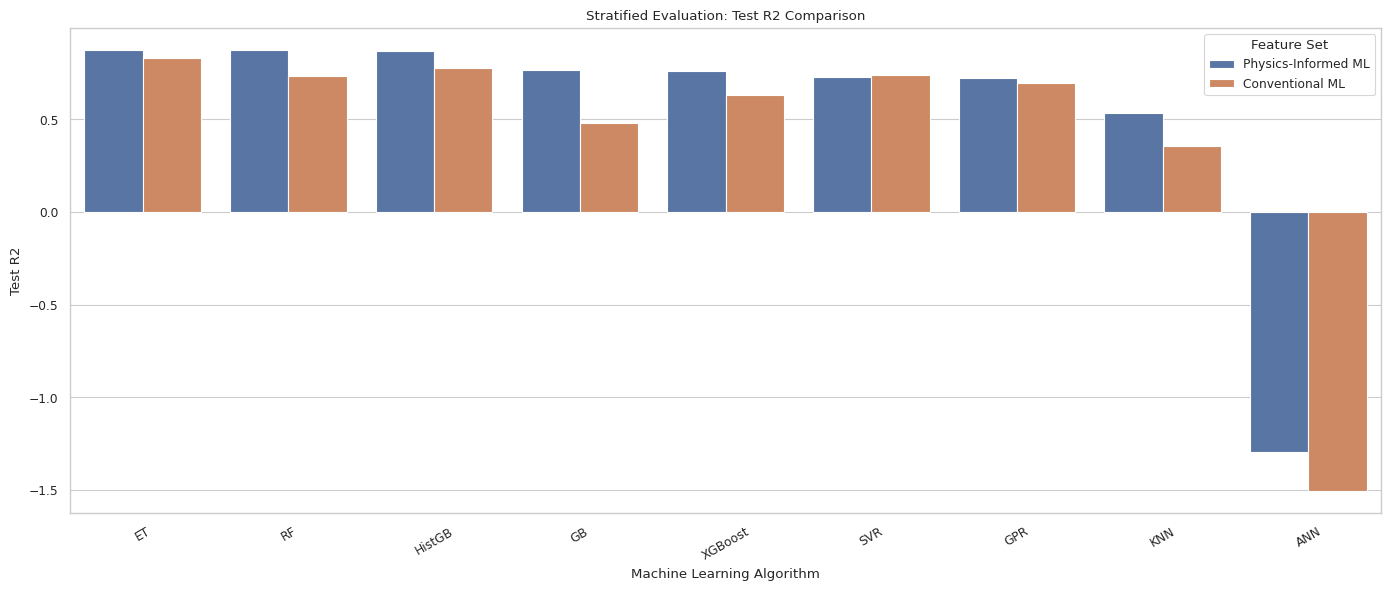

In [25]:

#PERFORMANCE COMPARISON


# Compare test RMSE
plt.figure(figsize=(14, 6))

sns.barplot(
    data=results_stratified_df,
    x="Model",
    y="Test RMSE",
    hue="Feature Set"
)

plt.title(
    "Stratified Evaluation: Test RMSE Comparison"
)

plt.ylabel("Test RMSE")
plt.xlabel("Machine Learning Algorithm")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


# Compare test R2
plt.figure(figsize=(14, 6))

sns.barplot(
    data=results_stratified_df,
    x="Model",
    y="Test R2",
    hue="Feature Set"
)

plt.title(
    "Stratified Evaluation: Test R2 Comparison"
)

plt.ylabel("Test R2")
plt.xlabel("Machine Learning Algorithm")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


In [26]:

# HYPERPARAMETER OPTIMIZATION


from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform

# Parameter search spaces
param_grids = {

    "ET": {

        "model__n_estimators": [200, 300, 500, 700],

        "model__max_depth": [None, 5, 8, 10, 15],

        "model__min_samples_split": [2, 3, 5, 8, 10],

        "model__min_samples_leaf": [1, 2, 3, 4, 5],

        "model__max_features": [0.6, 0.8, 1.0]

    },

    "RF": {

        "model__n_estimators": [200, 300, 500, 700],

        "model__max_depth": [None, 5, 8, 10, 15],

        "model__min_samples_split": [2, 3, 5, 8, 10],

        "model__min_samples_leaf": [1, 2, 3, 4, 5],

        "model__max_features": [0.6, 0.8, 1.0]

    },

    "HistGB": {

        "model__max_iter": [100, 150, 200, 300],

        "model__learning_rate": [0.01, 0.02, 0.03, 0.05, 0.1],

        "model__max_leaf_nodes": [5, 8, 10, 15, 20],

        "model__min_samples_leaf": [5, 10, 15, 20],

        "model__l2_regularization": [0.0, 0.1, 1.0, 5.0]

    }

}


# Store optimization results
tuning_results = []

best_tuned_models = {}


# Optimize both feature sets
for feature_name, (Xtr, Xte) in feature_sets.items():

    for model_name in ["ET", "RF", "HistGB"]:

        print("\n" + "=" * 60)

        print("Feature set:", feature_name)

        print("Model:", model_name)

        print("=" * 60)

        base_model = create_models()[model_name]

        search = RandomizedSearchCV(

            estimator=base_model,

            param_distributions=param_grids[model_name],

            n_iter=30,

            scoring="neg_root_mean_squared_error",

            cv=cv_splits,

            random_state=42,

            n_jobs=-1,

            verbose=1,

            refit=True

        )

        # Fit using training data only
        search.fit(Xtr, y_train)

        # Best model
        best_model = search.best_estimator_

        best_tuned_models[
            (feature_name, model_name)
        ] = best_model

        # Predictions
        train_pred = best_model.predict(Xtr)

        test_pred = best_model.predict(Xte)

        # Metrics
        train_r2 = r2_score(y_train, train_pred)

        test_r2 = r2_score(y_test, test_pred)

        test_rmse = np.sqrt(
            mean_squared_error(y_test, test_pred)
        )

        test_mae = mean_absolute_error(
            y_test, test_pred
        )

        tuning_results.append({

            "Feature Set": feature_name,

            "Model": model_name,

            "Best CV RMSE": -search.best_score_,

            "Train R2": train_r2,

            "Test R2": test_r2,

            "Test RMSE": test_rmse,

            "Test MAE": test_mae,

            "Best Parameters": search.best_params_

        })

        print("\nBest CV RMSE:", -search.best_score_)

        print("Best parameters:")

        print(search.best_params_)

        print("\nTest R2:", test_r2)

        print("Test RMSE:", test_rmse)


# Final tuning results
tuning_df = pd.DataFrame(tuning_results)

display(
    tuning_df.drop(
        columns=["Best Parameters"]
    ).round(4)
)



Feature set: Conventional ML
Model: ET
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best CV RMSE: 1.3889297188688186
Best parameters:
{'model__n_estimators': 700, 'model__min_samples_split': 3, 'model__min_samples_leaf': 1, 'model__max_features': 0.6, 'model__max_depth': 8}

Test R2: 0.8282776138292381
Test RMSE: 0.9700519057626573

Feature set: Conventional ML
Model: RF
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best CV RMSE: 1.571636125214074
Best parameters:
{'model__n_estimators': 700, 'model__min_samples_split': 3, 'model__min_samples_leaf': 1, 'model__max_features': 0.6, 'model__max_depth': 8}

Test R2: 0.7917133459829546
Test RMSE: 1.0683467608867097

Feature set: Conventional ML
Model: HistGB
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best CV RMSE: 1.474461091920968
Best parameters:
{'model__min_samples_leaf': 5, 'model__max_leaf_nodes': 15, 'model__max_iter': 300, 'model__learning_rate': 0.05, 'model__l2_regularization

,Feature Set,Model,Best CV RMSE,Train R2,Test R2,Test RMSE,Test MAE
0,Conventional ML,ET,1.3889,0.9583,0.8283,0.9701,0.5809
1,Conventional ML,RF,1.5716,0.9376,0.7917,1.0683,0.5705
2,Conventional ML,HistGB,1.4745,0.9775,0.6027,1.4756,0.8270
3,Physics-Informed ML,ET,1.2468,0.9826,0.8545,0.8929,0.4994
4,Physics-Informed ML,RF,1.2788,0.9625,0.8825,0.8025,0.5261
5,Physics-Informed ML,HistGB,1.3212,0.9455,0.6843,1.3153,0.6803


In [29]:
comparison_rows = []

for (feature_name, model_name), model in best_tuned_models.items():

    if feature_name == "Conventional ML":
        Xtr = X_train_raw
        Xte = X_test_raw

    elif feature_name == "Physics-Informed ML":
        Xtr = X_train_physics
        Xte = X_test_physics

    else:
        continue

    # Match the exact columns and their order used during model training
    expected_features = model.feature_names_in_

    Xtr = Xtr[expected_features]
    Xte = Xte[expected_features]

    y_train_pred = model.predict(Xtr)
    y_test_pred = model.predict(Xte)

    comparison_rows.append({
        "Feature Set": feature_name,
        "Model": model_name,
        "Train R2": r2_score(y_train, y_train_pred),
        "Test R2": r2_score(y_test, y_test_pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, y_test_pred)),
        "Test MAE": mean_absolute_error(y_test, y_test_pred)
    })

if comparison_rows:
    tuned_comparison = pd.DataFrame(comparison_rows)

    tuned_comparison = tuned_comparison.sort_values(
        by="Test RMSE"
    ).reset_index(drop=True)

    display(tuned_comparison.round(4))
else:
    print("No models were evaluated. Check the dictionary keys.")

,Feature Set,Model,Train R2,Test R2,Test RMSE,Test MAE
0,Physics-Informed ML,RF,0.9625,0.8825,0.8025,0.5261
1,Physics-Informed ML,ET,0.9826,0.8545,0.8929,0.4994
2,Conventional ML,ET,0.9583,0.8283,0.9701,0.5809
3,Conventional ML,RF,0.9376,0.7917,1.0683,0.5705
4,Physics-Informed ML,HistGB,0.9455,0.6843,1.3153,0.6803
5,Conventional ML,HistGB,0.9775,0.6027,1.4756,0.8270


,Feature,Importance Mean,Importance Std
0,AED,1.1892,0.1607
1,VED,0.5253,0.1529
2,LED,0.1357,0.0368
3,BLR,0.1242,0.0411
4,scan_speed_mm_s,0.0563,0.0262
5,BHR,0.0508,0.0093
6,laser_power_w,0.0371,0.0110
7,hatch_space_mm,0.0350,0.0095
8,spot_size_mm,0.0264,0.0253
9,layer_thickness_mm,0.0157,0.0151


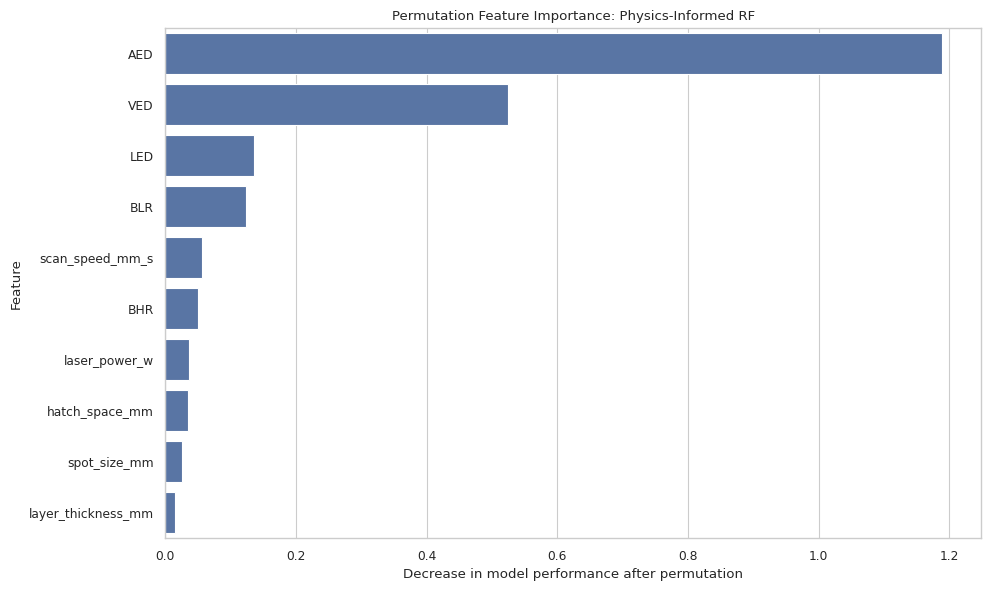

In [30]:
from sklearn.inspection import permutation_importance
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Select the best tuned model
best_model = best_tuned_models[
    ("Physics-Informed ML", "RF")
]

# Calculate permutation importance on the test set
perm_result = permutation_importance(
    best_model,
    X_test_physics,
    y_test,
    n_repeats=30,
    random_state=42,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

# Create importance table
importance_df = pd.DataFrame({
    "Feature": X_test_physics.columns,
    "Importance Mean": perm_result.importances_mean,
    "Importance Std": perm_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance Mean",
    ascending=False
).reset_index(drop=True)

display(importance_df.round(4))

# Plot
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance Mean",
    y="Feature"
)

plt.xlabel("Decrease in model performance after permutation")
plt.ylabel("Feature")
plt.title("Permutation Feature Importance: Physics-Informed RF")
plt.tight_layout()
plt.show()

## Key Findings and Discussion

### Mechanical and Process-Related Insights

- **Energy input plays an important role in relative-density prediction.** Areal Energy Density (AED) and Volumetric Energy Density (VED) were the two most influential derived features. Both descriptors represent the combined effects of multiple LPBF process parameters rather than their isolated contributions.

- **AED emerged as the dominant feature**, with a permutation importance of 1.1892. AED represents the nominal laser energy input per unit area and incorporates laser power, scan speed, and hatch spacing. Its strong predictive contribution suggests that the combined influence of these parameters is important for characterizing relative-density variations.

- **VED ranked second**, with an importance of 0.5253. It accounts for laser power, scan speed, hatch spacing, and layer thickness. VED provides a volumetric representation of nominal energy input, which is relevant to melting and consolidation of successive powder layers.

- **Energy input is closely associated with melt-pool behavior and defect formation.** Insufficient energy input can cause incomplete melting and lack-of-fusion defects. Excessive energy input can promote keyhole formation, vaporization, and melt-pool instability. These defects can contribute to porosity and reduced relative density.

- **Geometric ratios also contributed to the predictions.** Beam-to-Layer Ratio (BLR) had an importance of 0.1242, while Beam-to-Hatch Ratio (BHR) had an importance of 0.0508. These ratios describe the relationship between laser spot size, layer thickness, and hatch spacing, which are relevant to the spatial characteristics of laser-material interaction and track overlap.

- **Scan speed showed a greater individual contribution than most other raw process parameters.** Its importance was 0.0563. Mechanically, scan speed influences laser-material interaction time, melt-pool development, and the continuity of melting along the scan path.

- **The relatively low individual importance of laser power, hatch spacing, and layer thickness does not indicate that these parameters are mechanically insignificant.** Their combined effects are partly represented by the derived energy-density and geometric features.

### Machine Learning Performance

- Physics-informed feature engineering improved the predictive performance of Random Forest (RF), Extra Trees (ET), and HistGradientBoosting (HistGB) compared with their conventional counterparts.

- The physics-informed RF model achieved the best overall test performance, with an R² of **0.8825**, RMSE of **0.8025**, and MAE of **0.5261**.

- The physics-informed ET model achieved the lowest test MAE of **0.4994**, with an R² of 0.8545 and RMSE of 0.8929.

- Compared with conventional RF, physics-informed RF improved test R² from 0.7917 to 0.8825 and reduced RMSE from 1.0683 to 0.8025, representing an approximately **24.9% reduction in RMSE**.

- Permutation importance identified AED and VED as the dominant predictive features, followed by LED (0.1357) and BLR (0.1242).

### Overall Interpretation

The findings indicate that incorporating physics-derived descriptors can improve the prediction of relative density in IN718 LPBF. The results suggest that combined energy-input characteristics and geometric relationships provide useful information about the process conditions associated with density variation.

From a mechanical perspective, the importance of energy-density descriptors is consistent with the role of laser-material interaction, melt-pool formation, track overlap, and defect development in determining the quality of LPBF components.

However, AED, VED, and LED are mathematically related. Their permutation importance scores should therefore not be interpreted as independent physical effects or direct evidence of causal relationships. Furthermore, the dataset does not directly contain melt-pool measurements or porosity characterization. Experimental validation would be necessary to confirm the proposed physical mechanisms.